# Lab 5: Motor parameter identification

Fayozbek Yusupov, ID 240061

I followed the Experiment design in the Lab 5 README. I held the robot in the air and ran `motor_identification.qrs` on both wheels: left wheel = motor M4 and encoder E4, right wheel = motor M3 and encoder E3. The program gives every PWM level from -100 % to +100 % in 5 % steps: 2 s with the motor on, then 1 s with the motor off. In every cycle it writes the angle, the time and the PWM to a file. The battery was 11.2 V before and after every run.

The processing follows the course notebook `Motor_identification.ipynb`. Upload `steps5_M4.txt` and `steps5_M3.txt` from the `motor_data` folder in the next cell.

In [ ]:
from google.colab import files    # file work module
uploaded = files.upload()         # upload file context window

In [2]:
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization
from scipy import optimize          # data fitting
from scipy.integrate import odeint  # ordinary differential equation solver
import pandas as pd                 # tables

## 1. T_m and w_ss for every PWM level

For every PWM level I take its lines from the file, convert the time to seconds and the angle to radians, start both from zero and fit the model from the README with `curve_fit`:

$\theta(t) = \omega_{ss}(t - T_m + T_m e^{-t/T_m})$

I used the `bounds` option of `curve_fit` (T_m from 0.005 to 2 s), because without it the fit for the right wheel at 100 % went wrong. The voltage is $U = \text{PWM}/100 \cdot U_{battery}$ with $U_{battery}$ = 11.2 V. The tables below show $\omega_{ss}$ and $T_m$ for every PWM level, one table for each wheel.

In [3]:
U_battery = 11.2

def model(t, w_ss, T_m):
    return w_ss * (t - T_m + T_m * np.exp(-t / T_m))

def fit_file(name):
    angle, time, pwm = np.loadtxt(name, delimiter=',', unpack=True)
    time = time / 1000                  # SI conversion
    angle = angle * np.pi / 180         # SI conversion
    results = []
    for level in np.unique(pwm):
        if level == 0:
            continue
        t = time[pwm == level] - time[pwm == level][0]
        theta = angle[pwm == level] - angle[pwm == level][0]
        popt, pcov = optimize.curve_fit(model, t, theta, p0=[8, 0.1], bounds=([-60, 0.005], [60, 2]))
        results.append([level, popt[0], popt[1]])
    return np.array(results)

left = fit_file('steps5_M4.txt')
right = fit_file('steps5_M3.txt')

for res, name in [(left, 'Left wheel (M4)'), (right, 'Right wheel (M3)')]:
    table = pd.DataFrame({'PWM, %': res[:, 0],
                          'U, V': res[:, 0] / 100 * U_battery,
                          'w_ss, rad/s': res[:, 1],
                          'T_m, s': res[:, 2]})
    print(name)
    print(table.round(3))

Left wheel (M4)
    PWM, %   U, V  w_ss, rad/s  T_m, s
0   -100.0 -11.20      -13.862   0.046
1    -95.0 -10.64      -13.362   0.049
2    -90.0 -10.08      -12.539   0.064
3    -85.0  -9.52      -11.827   0.092
4    -80.0  -8.96      -11.475   0.099
5    -75.0  -8.40      -11.011   0.088
6    -70.0  -7.84      -10.299   0.130
7    -65.0  -7.28       -9.458   0.163
8    -60.0  -6.72       -9.223   0.175
9    -55.0  -6.16       -8.651   0.178
10   -50.0  -5.60       -8.278   0.174
11   -45.0  -5.04       -7.893   0.174
12   -40.0  -4.48       -7.480   0.207
13   -35.0  -3.92       -7.150   0.228
14   -30.0  -3.36       -6.162   0.269
15   -25.0  -2.80       -5.507   0.234
16   -20.0  -2.24       -4.815   0.251
17   -15.0  -1.68       -4.132   0.278
18   -10.0  -1.12       -3.364   0.357
19    -5.0  -0.56       -1.347   0.482
20     5.0   0.56        2.831   0.005
21    10.0   1.12        3.716   0.292
22    15.0   1.68        4.736   0.350
23    20.0   2.24        5.507   0.270
24    25.

At +5 % on the left wheel the fit did not work (T_m = 0.005 s, the lower limit): the wheel jumped forward and then slowed down.

## 2. Speed against voltage

The README model says $\omega_{ss} = U / k_e$, so for each wheel I fit this line to all points with `curve_fit` and get $k_e$. Both wheels already turn at ±5 %, so the dead zone is smaller than 5 %. I mark it as the red band between -5 % and +5 %.

left (M4): k_e = 0.714 V*s/rad
right (M3): k_e = 0.658 V*s/rad


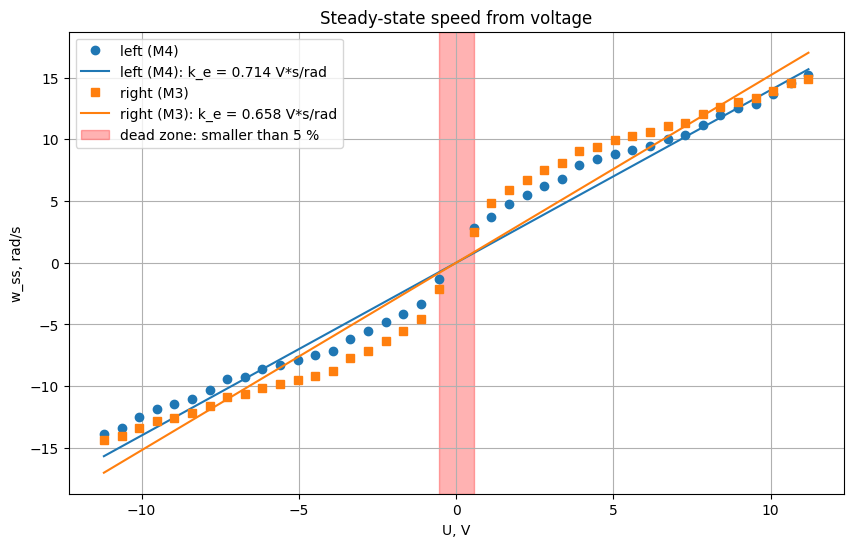

In [4]:
def speed(U, k_e):
    return U / k_e

plt.figure(figsize=(10, 6), dpi=100)
for res, name, mark in [(left, 'left (M4)', 'o'), (right, 'right (M3)', 's')]:
    U = res[:, 0] / 100 * U_battery
    popt, pcov = optimize.curve_fit(speed, U, res[:, 1], p0=[1])
    k_e = popt[0]
    points = plt.plot(U, res[:, 1], mark, label=name)
    plt.plot(U, speed(U, k_e), '-', color=points[0].get_color(), label=f'{name}: k_e = {k_e:.3f} V*s/rad')
    print(f'{name}: k_e = {k_e:.3f} V*s/rad')
plt.axvspan(-0.05 * U_battery, 0.05 * U_battery, color='red', alpha=0.3, label='dead zone: smaller than 5 %')
plt.xlabel('U, V')
plt.ylabel('w_ss, rad/s')
plt.title('Steady-state speed from voltage')
plt.grid()
plt.legend()
plt.show()

## 3. T_m against voltage

By the model $T_m = J R / (k_e k_m)$ depends only on the motor: the moment of inertia $J$, the resistance $R$ and the constants $k_e$ and $k_m$. So $T_m$ should be the same at every voltage. To check this, I plot $T_m$ from the tables against the voltage.

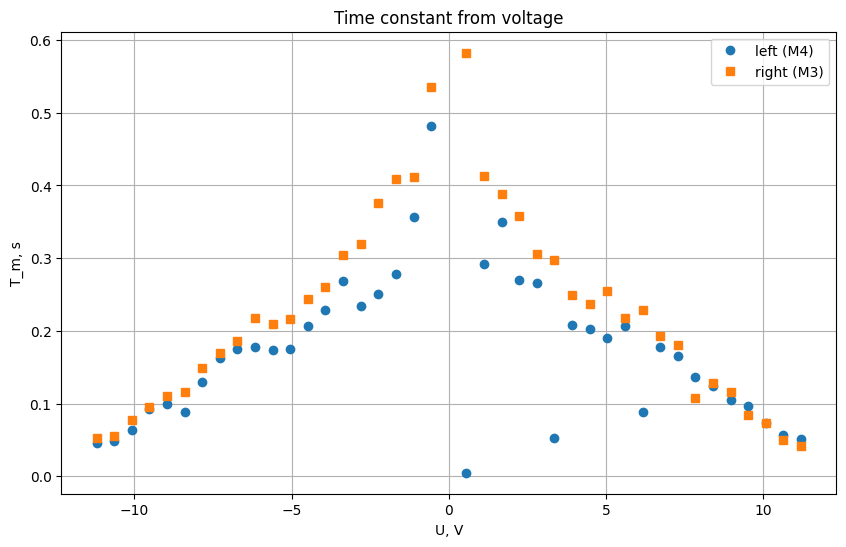

In [5]:
plt.figure(figsize=(10, 6), dpi=100)
for res, name, mark in [(left, 'left (M4)', 'o'), (right, 'right (M3)', 's')]:
    U = res[:, 0] / 100 * U_battery
    plt.plot(U, res[:, 2], mark, label=name)
plt.xlabel('U, V')
plt.ylabel('T_m, s')
plt.title('Time constant from voltage')
plt.grid()
plt.legend()
plt.show()

$T_m$ is not constant. For both wheels it is about 0.3-0.6 s at small voltage and about 0.05 s at ±11.2 V (100 %). Probably at small voltage the motor is only a little stronger than the friction, so the wheel speeds up slowly, and the model has no friction. At high PWM the wheel speeds up in about 50 ms, and with about 20 ms between my points there are only 2-3 points in the speed-up, so $T_m$ there is less accurate. The low points of the left wheel are the failed fit at +5 % and the steps at +30 % and +55 %, where the wheel started much faster than at the levels next to them.

## 4. One step: measured and simulated

The +50 % step of the left wheel, simulated with `motor` and `odeint` from the course notebook, with T_m from the fit and $k_e = U / \omega_{ss}$ for this step.

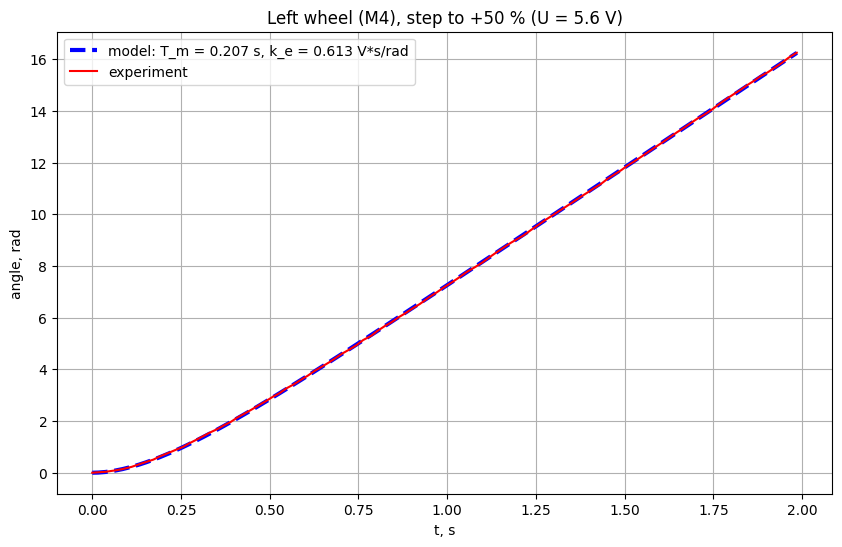

In [6]:
def motor(state, t):
    speed, angle = state                                            # motor state space
    state_dt = np.array([-speed/T_m + u/ (T_m * k_e), speed ])      # differential equation for the motor state
    return state_dt

angle, time, pwm = np.loadtxt('steps5_M4.txt', delimiter=',', unpack=True)
time = (time[pwm == 50] - time[pwm == 50][0]) / 1000            # SI conversion
angle = (angle[pwm == 50] - angle[pwm == 50][0]) * np.pi / 180  # SI conversion
popt, pcov = optimize.curve_fit(model, time, angle, p0=[8, 0.1])

T_m = popt[1]                                                   # electromechanical time constant
u = 50 / 100 * U_battery                                        # voltage at 50 %
k_e = u / popt[0]                                               # k_e = U / w_ss
init = [0, 0]                                                   # initial speed and angle
y = odeint(motor, init, time)                                   # numerical ode solution

plt.figure(figsize=(10, 6), dpi=100)
plt.plot(time, y[:, 1], 'b--', linewidth=3, label=f'model: T_m = {T_m:.3f} s, k_e = {k_e:.3f} V*s/rad')
plt.plot(time, angle, 'r-', linewidth=1.5, label='experiment')
plt.xlabel('t, s')
plt.ylabel('angle, rad')
plt.title('Left wheel (M4), step to +50 % (U = 5.6 V)')
plt.grid()
plt.legend()
plt.show()

## 5. Conclusions

The linear model $\omega_{ss} = U / k_e$ fails mostly at small PWM: there the wheels turn 2-3 times faster than the line, for example at 10 % the left wheel turns at 3.7 rad/s, but the line gives 1.6 rad/s. $T_m$ is not constant either: it is about 0.3-0.6 s at small PWM and about 0.05 s at 100 %. Both wheels already turn at ±5 %, so the dead zone is smaller than 5 %. The right wheel is faster than the left one at small and middle PWM (30 % faster at 10 % and 12 % at 50 %) but almost the same at 100 %, so its $k_e$ is smaller (0.66 instead of 0.71 V·s/rad). So next week the robot will not drive straight with the same PWM on both motors but turn to the left, and the odometry has to use the encoder angle of each wheel, not the PWM.